# UA-DETRAC: Dataset and Model Analysis

This notebook visualizes dataset distributions, annotations, and metadata to support Detection and Tracking experiments. Model evaluation charts are optional and require metric CSV files.

Run after `prepare_dataset.py` or `00b_run_pipeline.ipynb`. Supports local environments and Google Colab. Figures are saved to `outputs/ua_detrac/analysis/plots` without modifying the dataset.


In [11]:
from pathlib import Path
import os
import sys
import json
import warnings

import pandas as pd
import matplotlib.pyplot as plt

# Mount Drive on Colab; discover the repository from the working directory locally.
try:
    from google.colab import drive
    IN_COLAB = True
    drive.mount('/content/drive')
except ImportError:
    IN_COLAB = False

project_override = os.environ.get('UA_DETRAC_PROJECT')
candidates = [Path.cwd(), *Path.cwd().parents]
if project_override:
    candidates.insert(0, Path(project_override))
if IN_COLAB and not project_override:
    candidates.insert(0, Path('/content/drive/MyDrive/CS331/CS331-Vehicle-Tracking'))
ROOT_PATH = next(
    (path for path in candidates if (path / 'scripts/prepare_dataset.py').is_file()),
    None,
)
if ROOT_PATH is None:
    raise FileNotFoundError('Repository not found; set UA_DETRAC_PROJECT.')

# Override the dataset path if it is stored elsewhere.
default_dataset = (
    Path('/content/ua_detrac/dataset_v1.1')
    if IN_COLAB else ROOT_PATH / 'outputs/ua_detrac/dataset_v1.1'
)
DATASET = Path(os.environ.get(
    'UA_DETRAC_DATASET', os.environ.get('UA_DETRAC_OUTPUT', default_dataset)
))
required = [
    DATASET / 'canonical/annotations.csv',
    DATASET / 'metadata/sequences.csv',
    DATASET / 'metadata/annotated_frames.csv',
]
missing = [str(path) for path in required if not path.is_file()]
if missing:
    raise FileNotFoundError(
        'Dataset metadata is unavailable. Run prepare_dataset.py first: '
        + ', '.join(missing)
    )

PLOT_DIR = ROOT_PATH / 'outputs/ua_detrac/analysis/plots'
PLOT_DIR.mkdir(parents=True, exist_ok=True)

annotations = pd.read_csv(DATASET / 'canonical/annotations.csv')
sequences = pd.read_csv(DATASET / 'metadata/sequences.csv')
annotated_frames = pd.read_csv(DATASET / 'metadata/annotated_frames.csv')
overlap_path = DATASET / 'canonical/occlusion_regions.csv'
overlap_regions = (
    pd.read_csv(overlap_path) if overlap_path.is_file() else pd.DataFrame()
)

# Older metadata may store sence_weather under the weather column.
if 'sence_weather' not in sequences.columns:
    sequences['sence_weather'] = sequences.get('weather', '')
if 'camera_state' not in sequences.columns:
    sequences['camera_state'] = ''

# Recover speed and trajectory_length from attributes_json in older datasets.
if 'attributes_json' in annotations.columns:
    source_attributes = annotations['attributes_json'].fillna('{}').map(json.loads)
    for field in ['speed', 'trajectory_length']:
        if field not in annotations.columns:
            annotations[field] = source_attributes.map(lambda attrs: attrs.get(field))
        annotations[field] = pd.to_numeric(annotations[field], errors='coerce')
for field in ['speed', 'trajectory_length']:
    if field not in annotations.columns:
        annotations[field] = pd.NA

# Compute track summaries from canonical annotations for older metadata compatibility.
track_lengths = annotations.groupby(['sequence', 'track_id']).agg(
    annotated_frame_count=('frame_id', 'nunique'),
    first_annotated_frame=('frame_id', 'min'),
    last_annotated_frame=('frame_id', 'max'),
    trajectory_length_xml_min=('trajectory_length', 'min'),
    trajectory_length_xml_max=('trajectory_length', 'max'),
).reset_index()

# Join sequence metadata for analysis while preserving source annotations.
data = annotations.merge(
    sequences[['sequence', 'split', 'sence_weather', 'camera_state']],
    on='sequence',
    how='left',
)
print(f'Dataset: {DATASET}')
print(f'Objects: {len(annotations):,}; sequences: {sequences.sequence.nunique()}')
print(f'Plot output: {PLOT_DIR}')


Dataset: d:\ZB\Code\UIT\CS331\CS331-Vehicle-Tracking\outputs\ua_detrac\dataset_v1.1
Objects: 1,274,055; sequences: 100
Plot output: d:\ZB\Code\UIT\CS331\CS331-Vehicle-Tracking\outputs\ua_detrac\analysis\plots


## 1. Class Distribution by Split

Compare annotation counts across classes and train/validation/test splits to identify imbalance. These counts represent object annotations across frames, so the same vehicle can contribute multiple observations.


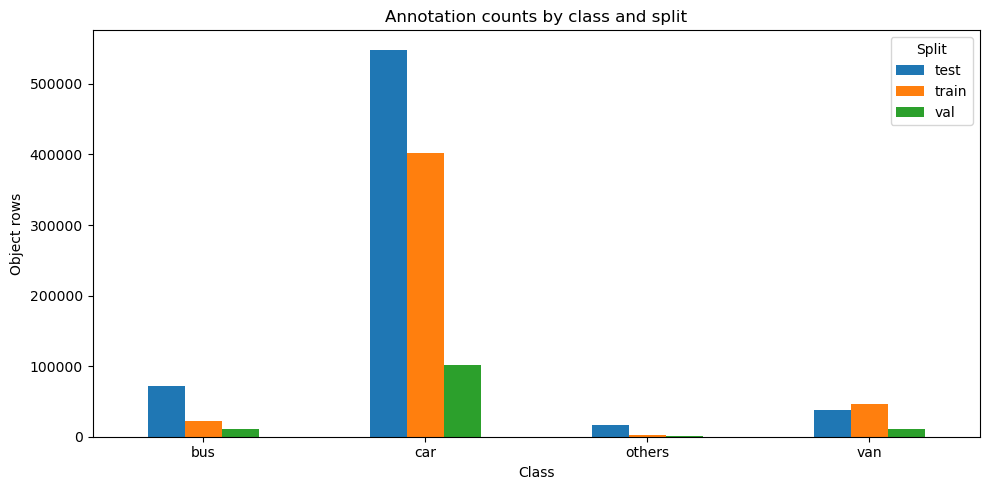

In [12]:
class_counts = pd.crosstab(data['class_name'], data['split'])
ax = class_counts.plot.bar(figsize=(10, 5), rot=0)
ax.set(title='Annotation counts by class and split', xlabel='Class', ylabel='Object rows')
ax.legend(title='Split')
plt.tight_layout()
plt.savefig(PLOT_DIR / '01_class_by_split.png', dpi=160)
plt.show()


## 2. Vehicles per Annotated Frame

Use `annotated_frames.csv` as the list of frames declared in XML, then left-join object counts. Declared frames with no targets receive a count of zero. Frames without XML entries remain separate and are not treated as negative samples.


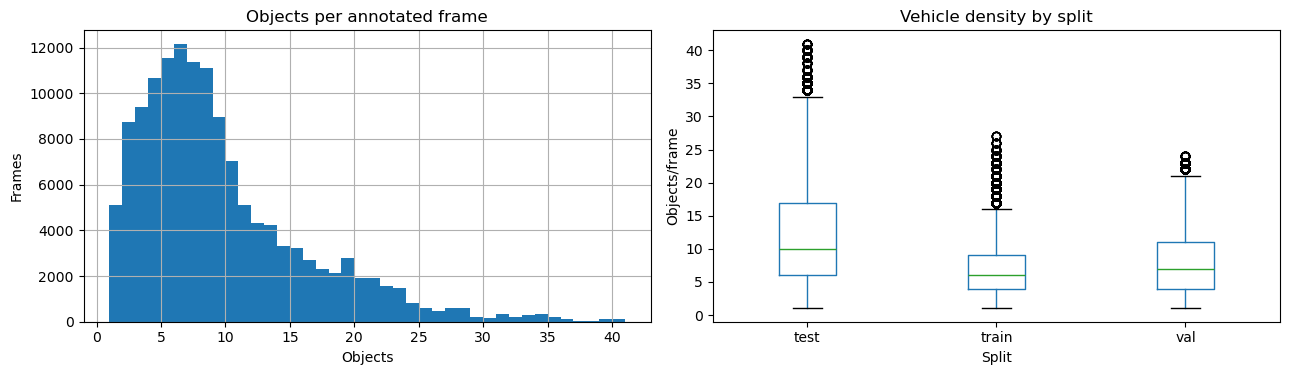

In [13]:
counts = annotations.groupby(['sequence', 'frame_id']).size().rename('object_count')
frame_counts = annotated_frames[['sequence', 'frame_id']].merge(
    counts, on=['sequence', 'frame_id'], how='left'
)
frame_counts['object_count'] = frame_counts['object_count'].fillna(0)
frame_counts = frame_counts.merge(
    sequences[['sequence', 'split']], on='sequence', how='left'
)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
frame_counts['object_count'].hist(bins=40, ax=axes[0])
axes[0].set(title='Objects per annotated frame', xlabel='Objects', ylabel='Frames')
frame_counts.boxplot(column='object_count', by='split', ax=axes[1], grid=False)
axes[1].set(title='Vehicle density by split', xlabel='Split', ylabel='Objects/frame')
fig.suptitle('')
plt.tight_layout()
plt.savefig(PLOT_DIR / '02_objects_per_frame.png', dpi=160)
plt.show()


## 3. Bounding Box Size and Aspect Ratio

Small vehicles can be challenging to detect. Bounding box area may have a skewed distribution, so the area chart uses logarithmic axes. These charts describe the annotations and do not define filtering thresholds.


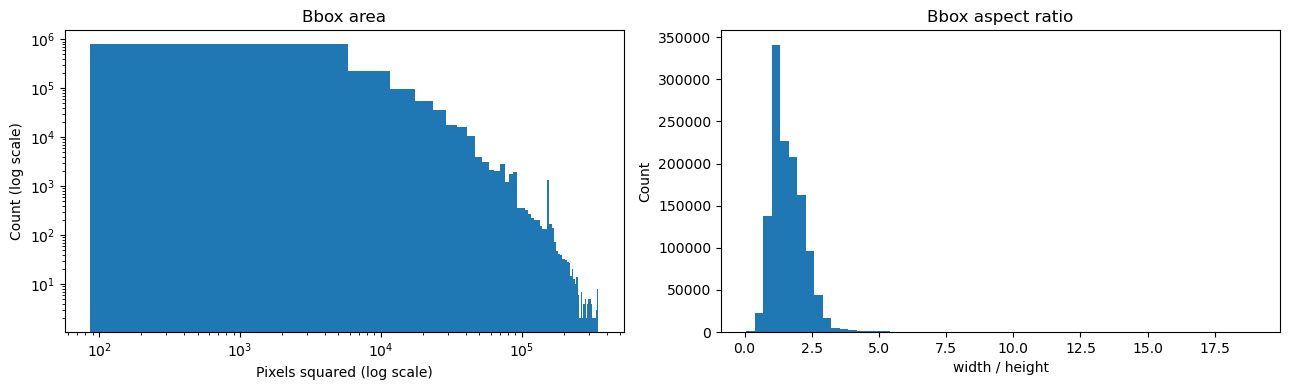

In [14]:
box_area = annotations['w'] * annotations['h']
aspect = annotations['w'] / annotations['h'].replace(0, pd.NA)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(box_area.clip(lower=1), bins=60, log=True)
axes[0].set_xscale('log')
axes[0].set(title='Bbox area', xlabel='Pixels squared (log scale)', ylabel='Count (log scale)')
axes[1].hist(aspect.dropna(), bins=60)
axes[1].set(title='Bbox aspect ratio', xlabel='width / height', ylabel='Count')
plt.tight_layout()
plt.savefig(PLOT_DIR / '03_bbox_size_shape.png', dpi=160)
plt.show()


## 4. Annotation Coverage by Sequence

Coverage measures the fraction of image frames declared in XML. An XML frame with no targets still counts as annotated. Image frames without XML entries are counted separately and require an explicit evaluation policy.


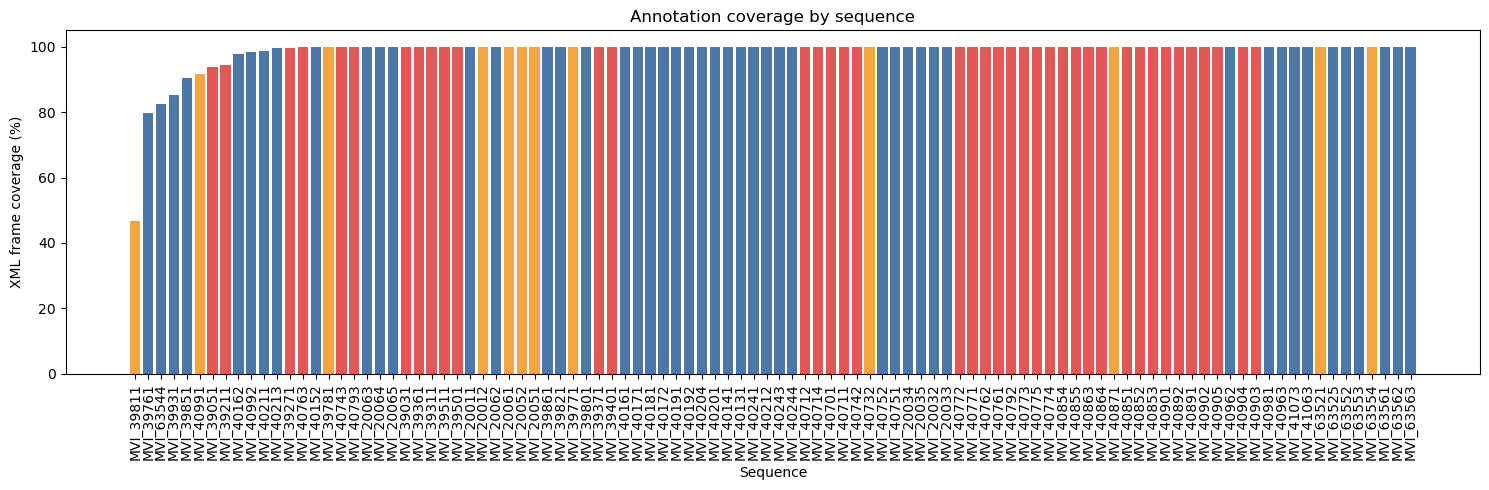

In [15]:
coverage = sequences.sort_values('annotation_coverage').copy()
colors = coverage['split'].map({'train': '#4c78a8', 'val': '#f2a541', 'test': '#e45756'})
fig, ax = plt.subplots(figsize=(15, 5))
ax.bar(coverage['sequence'], coverage['annotation_coverage'] * 100, color=colors)
ax.set(title='Annotation coverage by sequence', xlabel='Sequence', ylabel='XML frame coverage (%)')
ax.tick_params(axis='x', labelrotation=90)
plt.tight_layout()
plt.savefig(PLOT_DIR / '04_annotation_coverage.png', dpi=160)
plt.show()


## 5. Spatial Distribution of Vehicles

A heatmap of normalized bounding box centers shows where vehicles appear in the image. The vertical axis is inverted to match image coordinates. Differences across cameras may affect the combined distribution.


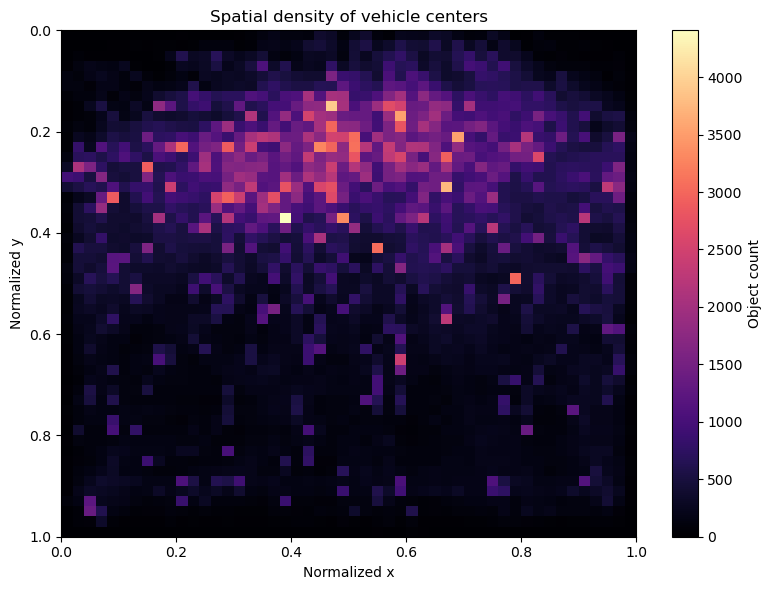

In [16]:
width = sequences['width'].dropna().mode()
height = sequences['height'].dropna().mode()
if width.empty or height.empty:
    print('Missing width/height in sequences.csv; skipping spatial heatmap.')
else:
    frame_width, frame_height = float(width.iloc[0]), float(height.iloc[0])
    centers_x = (annotations['x'] + annotations['w'] / 2) / frame_width
    centers_y = (annotations['y'] + annotations['h'] / 2) / frame_height
    fig, ax = plt.subplots(figsize=(8, 6))
    heat = ax.hist2d(centers_x, centers_y, bins=50, range=[[0, 1], [0, 1]], cmap='magma')
    ax.invert_yaxis()
    ax.set(title='Spatial density of vehicle centers', xlabel='Normalized x', ylabel='Normalized y')
    fig.colorbar(heat[3], ax=ax, label='Object count')
    plt.tight_layout()
    plt.savefig(PLOT_DIR / '05_spatial_density.png', dpi=160)
    plt.show()


## 6. Declared and Observed Track Lengths

`trajectory_length` comes from XML, while `annotated_frame_count` counts distinct frames containing the target in canonical annotations. Points away from the diagonal identify tracks worth inspecting; a discrepancy alone does not establish that the source XML is incorrect.


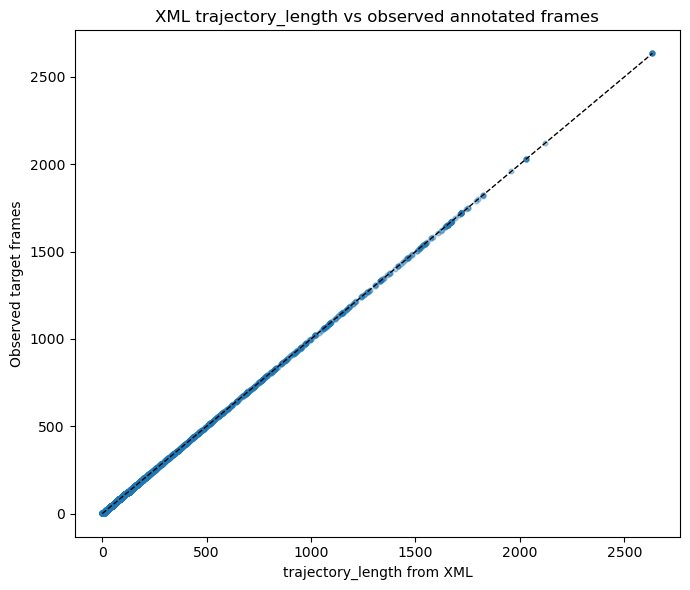

In [17]:
track_plot = track_lengths.dropna(
    subset=['trajectory_length_xml_min', 'annotated_frame_count']
)
if track_plot.empty:
    print('No trajectory_length values available for comparison with observed frames.')
else:
    fig, ax = plt.subplots(figsize=(7, 6))
    ax.scatter(
        track_plot['trajectory_length_xml_min'],
        track_plot['annotated_frame_count'],
        s=12, alpha=0.35,
    )
    limit = max(
        track_plot['trajectory_length_xml_min'].max(),
        track_plot['annotated_frame_count'].max(),
    )
    ax.plot([0, limit], [0, limit], '--', color='black', linewidth=1)
    ax.set(title='XML trajectory_length vs observed annotated frames',
           xlabel='trajectory_length from XML', ylabel='Observed target frames')
    plt.tight_layout()
    plt.savefig(PLOT_DIR / '06_track_length_xml_vs_observed.png', dpi=160)
    plt.show()


## 7. Speed by Class

Speed is stored for each target-frame. This chart shows the distribution of source values. Do not assume physical units unless they are confirmed by the source documentation. Boxplot outliers are hidden for readability; source values are preserved.


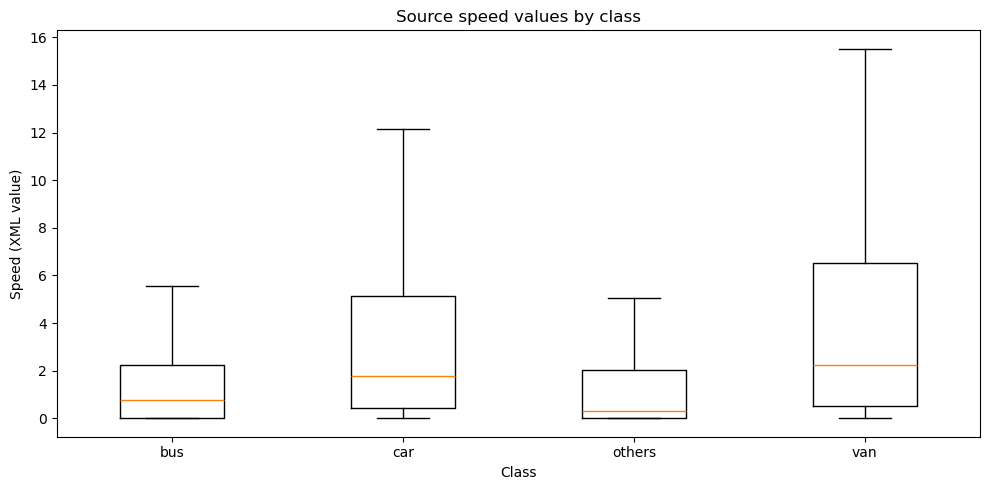

In [18]:
speed_data = data.dropna(subset=['speed'])
classes = sorted(speed_data['class_name'].dropna().unique())
values = [speed_data.loc[speed_data.class_name == name, 'speed'] for name in classes]
if values:
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.boxplot(values, showfliers=False)
    ax.set_xticks(range(1, len(classes) + 1), classes)
    ax.set(title='Source speed values by class', xlabel='Class', ylabel='Speed (XML value)')
    plt.tight_layout()
    plt.savefig(PLOT_DIR / '07_speed_by_class.png', dpi=160)
    plt.show()
else:
    print('NO speed values in canonical annotations.')


## 8. Weather and Camera State by Split

Compare sequence proportions by `sence_weather` and `camera_state` across splits. Different scene conditions may help explain differences in Detection or Tracking performance. These are sequence proportions, not frame or object proportions.


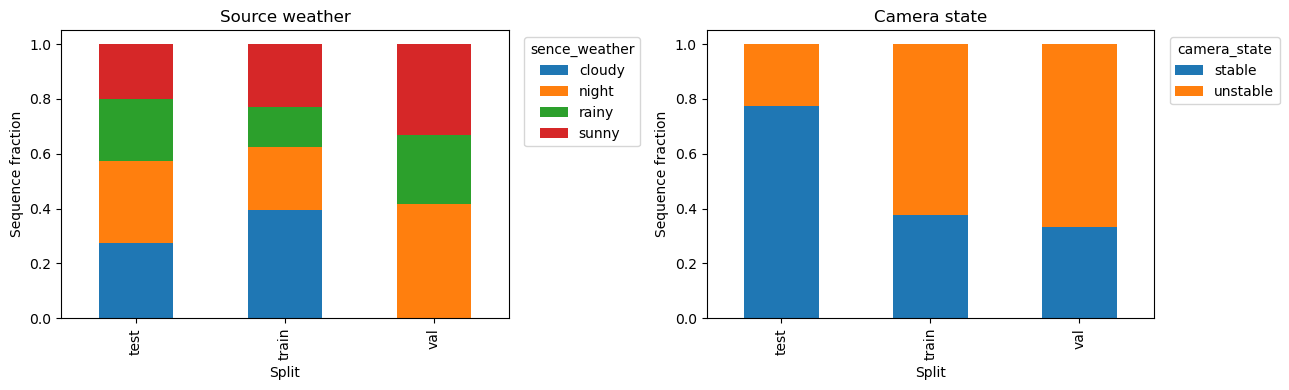

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for column, ax, title in [
    ('sence_weather', axes[0], 'Source weather'),
    ('camera_state', axes[1], 'Camera state'),
]:
    table = pd.crosstab(
        sequences['split'], sequences[column].fillna('unknown'), normalize='index'
    )
    table.plot.bar(stacked=True, ax=ax)
    ax.set(title=title, xlabel='Split', ylabel='Sequence fraction')
    ax.legend(title=column, bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.savefig(PLOT_DIR / '08_scene_conditions_by_split.png', dpi=160)
plt.show()


## 9. Occlusion Regions and Source Truncation Values

Occlusion regions are geometric annotations declared in XML. Plot truncation values as supplied by XML, including values outside `[0, 1]`. The histogram does not impose a valid range or filtering threshold. Region counts do not directly measure the number of occluded vehicles or an occlusion ratio.


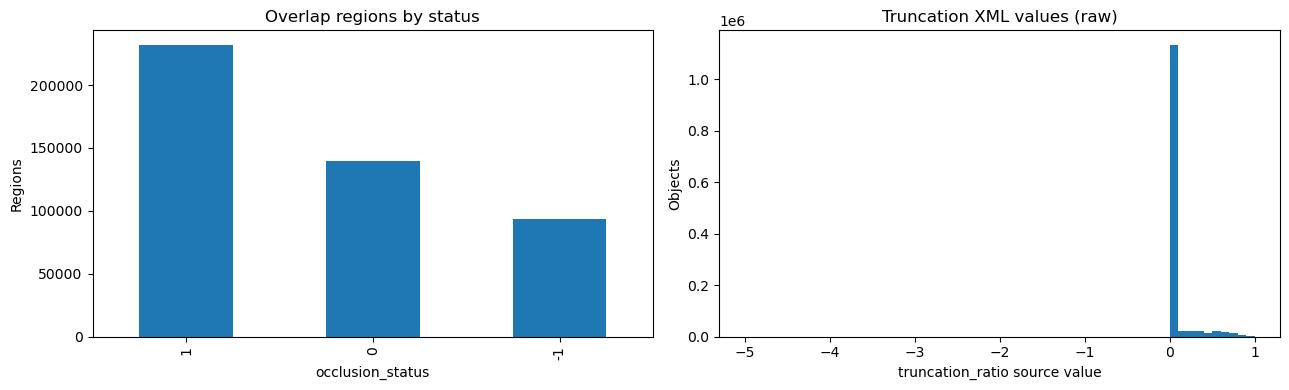

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
if not overlap_regions.empty and 'occlusion_status' in overlap_regions:
    overlap_regions['occlusion_status'].fillna('unknown').value_counts().plot.bar(ax=axes[0])
    axes[0].set(title='Overlap regions by status', xlabel='occlusion_status', ylabel='Regions')
else:
    axes[0].text(0.5, 0.5, 'No occlusion_regions.csv', ha='center', va='center')
truncation = annotations['truncation'].dropna()
if not truncation.empty:
    axes[1].hist(truncation, bins=60)
    axes[1].set(title='Truncation XML values (raw)', xlabel='truncation_ratio source value', ylabel='Objects')
else:
    axes[1].text(0.5, 0.5, 'No truncation values', ha='center', va='center')
plt.tight_layout()
plt.savefig(PLOT_DIR / '09_occlusion_truncation.png', dpi=160)
plt.show()


## 10. Optional Model Results

These charts require CSV files produced by training or evaluation. Set their paths through the environment variables shown in the next cell, or edit those path variables directly.

Expected columns:

- `detection_metrics.csv`: `class_name, precision, recall, ap50, ap50_95`.
- `learning_curve.csv`: `train_images, map50, map50_95`.
- `tracking_metrics.csv`: `sequence, HOTA, IDF1, MOTA, IDS, FP, FN`. The sequence charts use available HOTA, IDF1, and MOTA columns. Optional columns include `sence_weather`, `camera_state`, and `mean_objects_per_frame`.

Compare results using the same evaluation split, protocol, and documented score scale. The grouped metric table reports arithmetic means across sequences.


In [ ]:
# Optional metric CSVs: set environment variables or edit the paths below.
detection_metrics_path = Path(os.environ.get(
    'UA_DETRAC_DETECTION_METRICS', ROOT_PATH / 'outputs/metrics/detection_metrics.csv'
))
learning_curve_path = Path(os.environ.get(
    'UA_DETRAC_LEARNING_CURVE', ROOT_PATH / 'outputs/metrics/learning_curve.csv'
))
tracking_metrics_path = Path(os.environ.get(
    'UA_DETRAC_TRACKING_METRICS', ROOT_PATH / 'outputs/metrics/tracking_metrics.csv'
))

if detection_metrics_path.is_file():
    dm = pd.read_csv(detection_metrics_path)
    required = {'class_name', 'precision', 'recall', 'ap50', 'ap50_95'}
    if required.issubset(dm.columns):
        metrics = dm.set_index('class_name')[['precision', 'recall', 'ap50', 'ap50_95']]
        ax = metrics.plot.bar(figsize=(10, 5))
        ax.set(title='Detection metrics by class', ylabel='Score')
        plt.tight_layout()
        plt.savefig(PLOT_DIR / '10_detection_metrics.png', dpi=160)
        plt.show()
    else:
        print(f'Detection metrics missing columns: {sorted(required - set(dm.columns))}')
else:
    print(f'Detection metrics file not found: {detection_metrics_path}')

if learning_curve_path.is_file():
    lc = pd.read_csv(learning_curve_path)
    required = {'train_images', 'map50', 'map50_95'}
    if required.issubset(lc.columns):
        ax = lc.sort_values('train_images').set_index('train_images')[['map50', 'map50_95']].plot(marker='o')
        ax.set(title='Detection learning curve', xlabel='Training images', ylabel='mAP')
        plt.tight_layout()
        plt.savefig(PLOT_DIR / '11_detection_learning_curve.png', dpi=160)
        plt.show()
    else:
        print(f'Learning curve missing columns: {sorted(required - set(lc.columns))}')
else:
    print(f'Learning curve file not found: {learning_curve_path}')

if tracking_metrics_path.is_file():
    tm = pd.read_csv(tracking_metrics_path)
    metric_columns = [c for c in ['HOTA', 'IDF1', 'MOTA'] if c in tm.columns]
    if {'sequence', *metric_columns}.issubset(tm.columns) and metric_columns:
        tm = tm.merge(
            sequences[['sequence', 'sence_weather', 'camera_state']],
            on='sequence', how='left', suffixes=('', '_metadata'),
        )
        fig, axes = plt.subplots(1, len(metric_columns), figsize=(6 * len(metric_columns), 4))
        if len(metric_columns) == 1:
            axes = [axes]
        for metric, ax in zip(metric_columns, axes):
            tm.sort_values(metric).plot.bar(x='sequence', y=metric, ax=ax, legend=False)
            ax.set(title=f'{metric} by sequence', xlabel='Sequence', ylabel=metric)
            ax.tick_params(axis='x', labelrotation=90)
        plt.tight_layout()
        plt.savefig(PLOT_DIR / '12_tracking_metrics_by_sequence.png', dpi=160)
        plt.show()
        group_column = next((c for c in ['sence_weather', 'camera_state'] if c in tm.columns), None)
        if group_column:
            display(tm.groupby(group_column)[metric_columns].mean().sort_index())
    else:
        print('Tracking CSV requires sequence and at least one of HOTA, IDF1, or MOTA.')
else:
    print(f'Tracking metrics file not found: {tracking_metrics_path}')

print(f'Generated figures are saved to: {PLOT_DIR}')
